# NCAA Women's Tournament Outcome Prediction

**Author:** Shyla Khullar  
**Tools:** R, tidyverse, tidymodels, ggplot2, Jupyter Notebook

## Project overview

This project investigates whether conference win percentage, regional win
percentage, and conference rank can help predict how far a team advances in the
NCAA Division I Women's Basketball Tournament. I use exploratory data analysis
and a multiclass K-nearest neighbours (KNN) classifier to study tournament
appearances from 1982 through 2018.

The analysis was originally completed as an individual UBC DSCI 100 project.
This portfolio version removes course instructions and reorganizes the original
work for easier review. The modelling choices, code, results, and conclusions
remain based on my original analysis.


## Research question

**Can a team's conference win percentage, regional win percentage, and
conference rank be used to predict how far it advances in the NCAA Women's
Basketball Tournament?**

This is a multiclass classification problem because the response variable,
`tourney_finish`, contains discrete tournament outcomes rather than a continuous
numeric value.


## Data

The dataset contains 2,092 historical NCAA Division I Women's Basketball
Tournament appearances from 1982 through 2018. It was sourced from NCAA records
and published by the Diverse Data Hub.

**Source:** [Women's March Madness dataset](https://raw.githubusercontent.com/diverse-data-hub/diversedata/refs/heads/main/data-clean/womensmarchmadness.csv)


In [2]:
library(tidyverse)
womens_march_madness <- read_csv("https://raw.githubusercontent.com/diverse-data-hub/diversedata/refs/heads/main/data-clean/womensmarchmadness.csv")
womens_march_madness |>
head()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Rows: 2092 Columns: 20
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (6): school, conference, division, bid, first_game_at_home, tourney_finish
dbl (14): year, seed, conf_wins, conf_losses, conf_wins_pct, conf_rank, reg_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


year,school,seed,conference,conf_wins,conf_losses,conf_wins_pct,conf_rank,division,reg_wins,reg_losses,reg_wins_pct,bid,first_game_at_home,tourney_wins,tourney_losses,tourney_finish,total_wins,total_losses,total_wins_pct
<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1982,Arizona St.,4,Western Collegiate,NA,NA,NA,NA,NA,23,6,79.3,at-large,Y,1,1,top_16_loss,24,7,77.4
1982,Auburn,7,Southeastern,NA,NA,NA,NA,NA,24,4,85.7,at-large,N,0,1,first_round_loss,24,5,82.8
1982,Cheyney,2,Independent,NA,NA,NA,NA,NA,24,2,92.3,at-large,Y,4,1,top_2_loss,28,3,90.3
1982,Clemson,5,Atlantic Coast,6,3,66.7,4,NA,20,11,64.5,at-large,N,0,1,first_round_loss,20,12,62.5
1982,Drake,4,Missouri Valley,NA,NA,NA,NA,NA,26,6,81.3,auto,Y,2,1,top_8_loss,28,7,80.0
1982,East Carolina,6,Independent,NA,NA,NA,NA,NA,19,7,73.1,at-large,N,0,1,first_round_loss,19,8,70.4


## Data preparation


In [3]:
# selecting the variables needed to answer the research question
NCAA_tidy <- womens_march_madness |>
    select(conf_wins_pct, reg_wins_pct, conf_rank, tourney_finish)|> 
#Convert tournament finish into an ordered factor from earliest loss to champion
    mutate(tourney_finish = factor(tourney_finish, 
                               levels = c("opening_round_loss", "first_round_loss",
                                          "second_round_loss", "top_16_loss",
                                          "top_8_loss", "top_4_loss", "top_2_loss",
                                          "champ"), ordered = TRUE))|>
#Remove rows with missing values after selected variables
drop_na(conf_wins_pct, reg_wins_pct, conf_rank, tourney_finish)
#Show the first 6 rows of the tidied data
head(NCAA_tidy)

conf_wins_pct,reg_wins_pct,conf_rank,tourney_finish
<dbl>,<dbl>,<dbl>,<ord>
66.7,64.5,4,first_round_loss
85.7,78.6,1,top_4_loss
84.6,82.1,2,top_16_loss
100.0,86.2,1,first_round_loss
75.0,73.1,2,first_round_loss
83.3,66.7,1,first_round_loss


## Exploratory data analysis

I first examined the distributions, missingness, and relationships among the
three predictors and the tournament outcome. This step helped identify class
imbalance and supported the later model evaluation.


### Summary statistics


In [4]:
#calculate the mean,min, and max for each numeric value
NCAA_tidy |>
pivot_longer(cols = c(conf_wins_pct, reg_wins_pct, conf_rank), 
             names_to = "variable", 
             values_to = "value") |>
group_by(variable) |>
summarize(mean = mean(value, na.rm = TRUE),
          min = min(value, na.rm = TRUE),
          max = max(value, na.rm = TRUE))

variable,mean,min,max
<chr>,<dbl>,<dbl>,<dbl>
conf_rank,2.295421,1.0,10
conf_wins_pct,77.166371,21.4,100
reg_wins_pct,75.996504,41.4,100


### Missing values in the original dataset


In [5]:
# Counting the number of missing values in each variable
womens_march_madness |>
mutate(across(everything (), as.character)) |>
pivot_longer(everything(), names_to = "variable", 
             values_to = "value") |>
group_by(variable) |>
summarize(missing = sum(is.na(value)))

variable,missing
<chr>,<int>
bid,0
conf_losses,61
conf_rank,61
conf_wins,61
conf_wins_pct,61
conference,0
division,1996
first_game_at_home,0
reg_losses,0


### Average conference win percentage by outcome


In [6]:
NCAA_tidy |>
group_by(tourney_finish) |>
summarize(mean_conf_wins_pct = mean(conf_wins_pct, na.rm = TRUE))

tourney_finish,mean_conf_wins_pct
<ord>,<dbl>
opening_round_loss,91.70000
first_round_loss,75.83082
second_round_loss,73.51667
top_16_loss,78.65775
top_8_loss,84.76377
top_4_loss,87.57286
top_2_loss,90.98235
champ,91.42571


### Predictor and outcome distributions


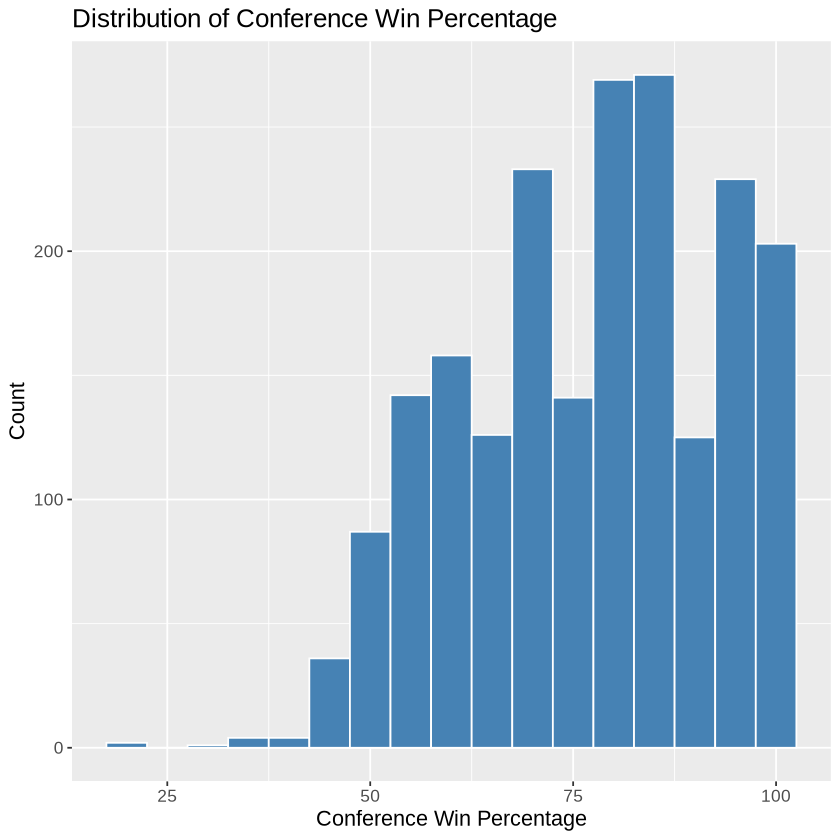

In [7]:
conf_wins_hist <- ggplot(NCAA_tidy, aes(x = conf_wins_pct)) +
geom_histogram(binwidth = 5, fill = "steelblue", color = "white")+
labs(title = "Distribution of Conference Win Percentage", 
     x = "Conference Win Percentage", 
     y = "Count") +
theme(text = element_text(size = 13)) 
conf_wins_hist

In [8]:
tourney_props <- NCAA_tidy |>
count(tourney_finish) |>
mutate(proportion = n/ sum(n))
tourney_props

tourney_finish,n,proportion
<ord>,<int>,<dbl>
opening_round_loss,1,0.0004923683
first_round_loss,941,0.4633185623
second_round_loss,528,0.2599704579
top_16_loss,284,0.1398325948
top_8_loss,138,0.0679468242
top_4_loss,70,0.0344657804
top_2_loss,34,0.0167405219
champ,35,0.0172328902


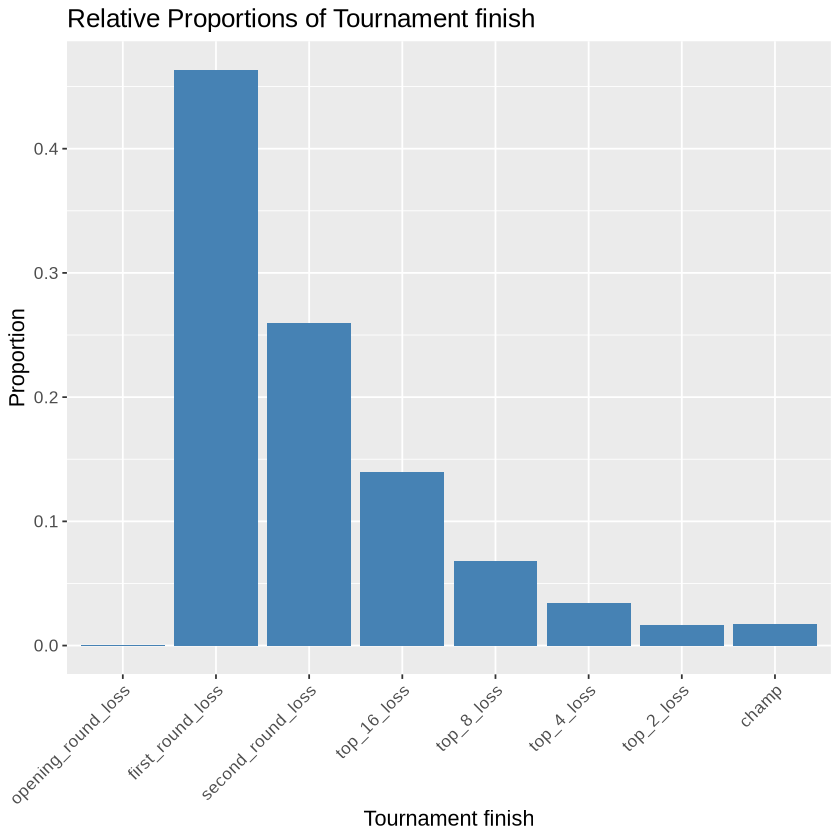

In [9]:
tourney_proportions_plot <- ggplot(tourney_props, aes(x = tourney_finish, y = proportion)) + 
geom_bar(stat = "identity", fill = "steelblue") + 
labs(title = "Relative Proportions of Tournament finish", x = "Tournament finish", y = "Proportion")+
theme(axis.text.x = element_text(angle = 45, hjust = 1), text = element_text(size = 13)) 
tourney_proportions_plot

### Conference performance and tournament advancement

Average conference win percentage generally rises for teams advancing to later
rounds. The opening-round category is an exception because it contains only one
observation and appeared only in the 1983 tournament, so its average is not
representative.


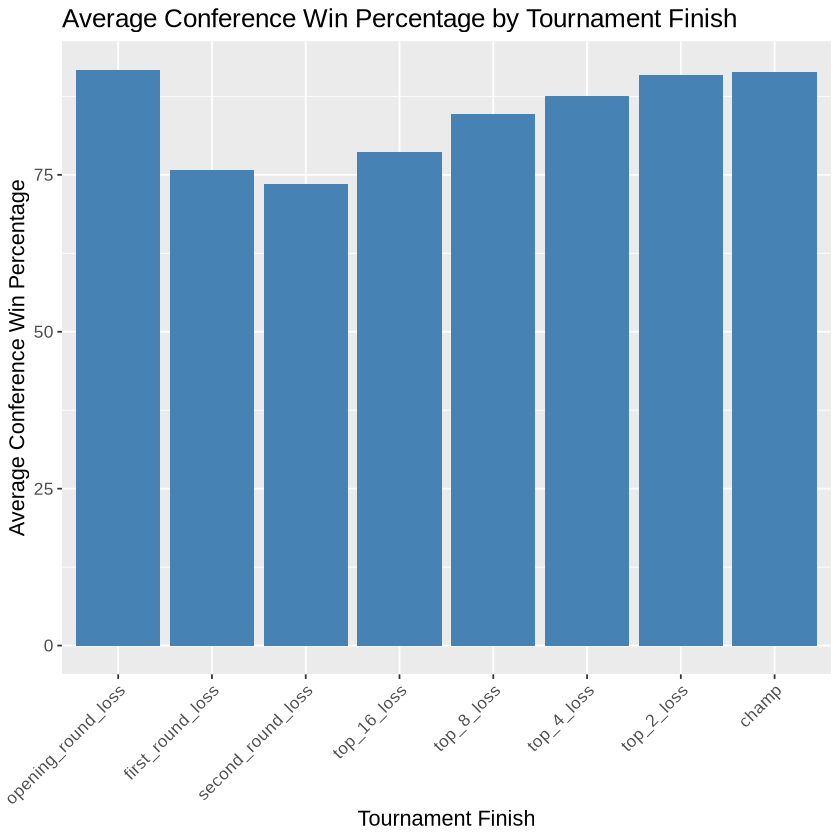

In [10]:
mean_conf_wins <- NCAA_tidy |>
  group_by(tourney_finish) |>
  summarize(mean_conf_wins_pct = mean(conf_wins_pct, na.rm = TRUE)) |>
  ggplot(aes(x = tourney_finish, y = mean_conf_wins_pct)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  labs(title = "Average Conference Win Percentage by Tournament Finish",
       x = "Tournament Finish",
       y = "Average Conference Win Percentage") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),text = element_text(size = 13))
mean_conf_wins

Average conference rank generally improves as teams advance further (a lower
numeric rank is better). Champions do not have the absolute lowest average rank,
which suggests that conference standing alone cannot fully explain tournament
success.


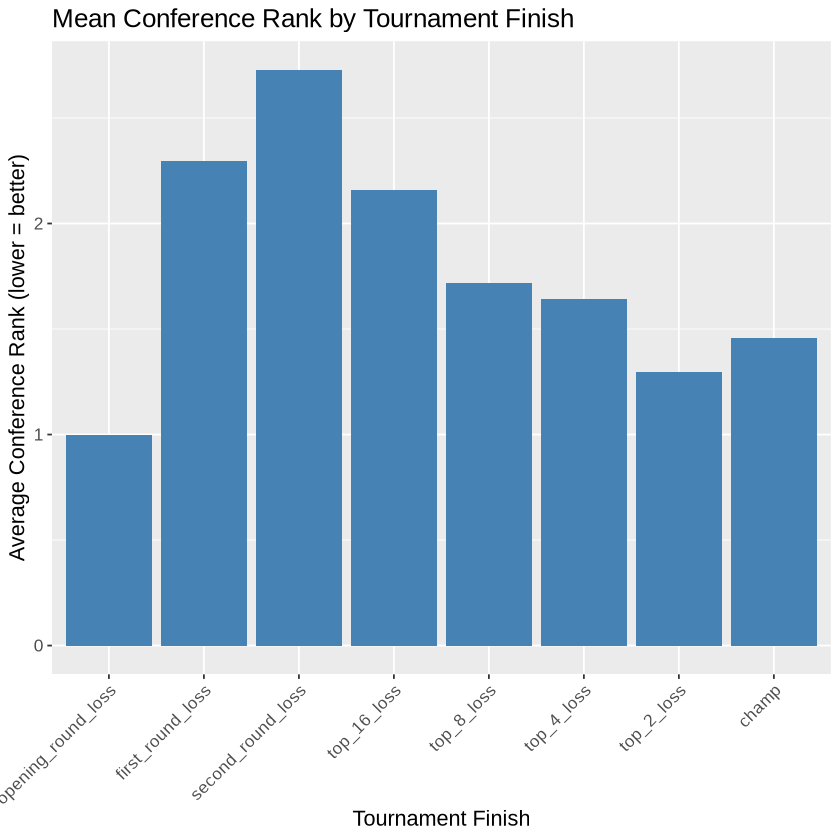

In [11]:
conf_rank_plot <- NCAA_tidy |>
  group_by(tourney_finish) |>
  summarize(mean_conf_rank = mean(conf_rank, na.rm = TRUE)) |>
  ggplot(aes(x = tourney_finish, y = mean_conf_rank)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  labs(title = "Mean Conference Rank by Tournament Finish",
       x = "Tournament Finish",
       y = "Average Conference Rank (lower = better)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),text = element_text(size = 13))
conf_rank_plot

## Modelling approach

I used a K-nearest neighbours classifier because the target contains multiple
categorical outcomes. The predictors were centred and scaled so their different
measurement ranges would not distort distance calculations. I used a stratified
75/25 train-test split and five-fold cross-validation on the training data. Odd
values of K from 1 through 25 were evaluated, and the value with the highest
cross-validation accuracy was selected before testing the final model on unseen
data.

KNN is sensitive to the selected K and to class imbalance. Accuracy is reported
alongside a confusion matrix so performance across individual tournament outcomes
can also be examined.


In [12]:
#load the tidymodels package for tools needed for KNN classification model. 
library(tidymodels)
# set the same seed so the train/test split and cross validation results are reproducible 
set.seed(1234)
#select the response and predictor variables needed for the model and then remove missing values 
NCAA_model_data <- NCAA_tidy |>
select(tourney_finish, conf_wins_pct, reg_wins_pct, conf_rank) |>
drop_na() 

#split the data into 75% training and 25% testing data which is stratified by tourney finish 
NCAA_split <- initial_split(NCAA_model_data, prop = 0.75, strata = tourney_finish)
NCAA_train <- training(NCAA_split)
NCAA_test <- testing(NCAA_split) 

# Create a recipe that predicts tournament finish from three predictor variables 
NCAA_recipe <- recipe(tourney_finish ~ conf_wins_pct + reg_wins_pct + conf_rank, data = NCAA_train) |>
#scale and center predictions to standardize data for fair cotribution to KNN distance calculations 
step_scale(all_predictors()) |>
step_center(all_predictors()) 

#specify a KNN classification model and tune the number of neighbors
knn_spec <- nearest_neighbor(weight_func = "rectangular", neighbors = tune()) |>
set_engine("kknn") |>
set_mode("classification") 

#create 5-fold cross-validation on training data which is stratified by tournament finish
NCAA_vfold <- vfold_cv(NCAA_train, v = 5, strata = tourney_finish) 

#combine recipe and model into workflow
knn_workflow <- workflow() |>
add_recipe(NCAA_recipe) |>
add_model(knn_spec) 

#try odd k values from 1-25 and collect cross validation performance metrics
K_vals <- tibble(neighbors = seq(from = 1, to = 25, by = 2))
knn_results <- knn_workflow |>
tune_grid(resamples = NCAA_vfold, grid = K_vals) |>
collect_metrics() 
knn_results

── Attaching packages ────────────────────────────────────── tidymodels 1.1.1 ──

✔ broom        1.0.6     ✔ rsample      1.2.1
✔ dials        1.3.0     ✔ tune         1.1.2
✔ infer        1.0.7     ✔ workflows    1.1.4
✔ modeldata    1.4.0     ✔ workflowsets 1.0.1
✔ parsnip      1.2.1     ✔ yardstick    1.3.1
✔ recipes      1.1.0     

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() masks purrr::discard()
✖ dplyr::filter()   masks stats::filter()
✖ recipes::fixed()  masks stringr::fixed()
✖ dplyr::lag()      masks stats::lag()
✖ yardstick::spec() masks readr::spec()
✖ recipes::step()   masks stats::step()
• Dig deeper into tidy modeling with R at https://www.tmwr.org

→ A | warning: ✖ No observations were detected in `truth` for level: opening_round_loss.
               ℹ Computation will proceed by ignoring those levels.

There were issues with some computations   A: x1

There were issues with some computations   A: x2

There were 

neighbors,.metric,.estimator,mean,n,std_err,.config
<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
1,accuracy,multiclass,0.4113198,5,0.011011826,Preprocessor1_Model01
1,roc_auc,hand_till,0.5305423,5,0.008571221,Preprocessor1_Model01
3,accuracy,multiclass,0.4060782,5,0.007622545,Preprocessor1_Model02
3,roc_auc,hand_till,0.5497602,5,0.008937968,Preprocessor1_Model02
5,accuracy,multiclass,0.4060609,5,0.014715710,Preprocessor1_Model03
5,roc_auc,hand_till,0.5542019,5,0.008768523,Preprocessor1_Model03
7,accuracy,multiclass,0.4100104,5,0.011440248,Preprocessor1_Model04
7,roc_auc,hand_till,0.5551392,5,0.011550126,Preprocessor1_Model04
9,accuracy,multiclass,0.4238090,5,0.014504075,Preprocessor1_Model05


### Selected number of neighbours


In [13]:
#select the K-value with the highest cross validation accuracy 
best_k <- knn_results |>
filter(.metric == "accuracy") |>
arrange(-mean) |>
slice(1) 
best_k

neighbors,.metric,.estimator,mean,n,std_err,.config
<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
21,accuracy,multiclass,0.4310157,5,0.006040096,Preprocessor1_Model11


### Test-set predictions


In [14]:
#finalize the workflow using the best K value found during tuning 
final_knn_workflow <- knn_workflow |>
finalize_workflow(best_k) 
#fit the final KNN model on training data
final_knn_fit <- final_knn_workflow |>
fit(data = NCAA_train) 

#use the final model to predict tournament finish for the test data 
NCAA_predictions <- predict(final_knn_fit, NCAA_test) |>
bind_cols(NCAA_test) 
NCAA_predictions

.pred_class,tourney_finish,conf_wins_pct,reg_wins_pct,conf_rank
<fct>,<ord>,<dbl>,<dbl>,<dbl>
first_round_loss,top_4_loss,85.7,78.6,1
second_round_loss,top_16_loss,84.6,82.1,2
first_round_loss,first_round_loss,83.3,66.7,1
first_round_loss,top_16_loss,75.0,76.7,1
second_round_loss,top_4_loss,50.0,80.0,3
second_round_loss,first_round_loss,76.9,75.9,2
second_round_loss,top_16_loss,75.0,83.3,1
first_round_loss,first_round_loss,88.9,78.6,1
first_round_loss,top_8_loss,92.9,82.1,1


### Test-set performance


In [15]:
#calculate model performance on test set using the classification metrics 
NCAA_metrics <- NCAA_predictions |>
metrics(truth = tourney_finish, estimate = .pred_class) 
NCAA_metrics

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.4577603
kap,multiclass,0.1943755


### Confusion matrix


In [16]:
#create a confusion matrix to compare predicted tournament finishes with the actual ones
NCAA_conf_mat <- NCAA_predictions |>
conf_mat(truth = tourney_finish, estimate = .pred_class) 
NCAA_conf_mat

                    Truth
Prediction           opening_round_loss first_round_loss second_round_loss
  opening_round_loss                  0                0                 0
  first_round_loss                    0              146                46
  second_round_loss                   0               74                75
  top_16_loss                         0               13                 9
  top_8_loss                          0                0                 2
  top_4_loss                          0                1                 0
  top_2_loss                          0                0                 0
  champ                               0                0                 0
                    Truth
Prediction           top_16_loss top_8_loss top_4_loss top_2_loss champ
  opening_round_loss           0          0          0          0     0
  first_round_loss            20          8          3          1     0
  second_round_loss           35         17          7   

## Results

The tuned model selected **K = 21**, achieved approximately **43.1% mean
cross-validation accuracy**, and reached **45.8% accuracy on the held-out test
set**. The Cohen's kappa estimate was approximately **0.194**.

The confusion matrix shows that the model performed best on the more common
first-round and second-round outcomes. It struggled with later-round outcomes,
including championship appearances, because those categories contained far
fewer observations. The results indicate that regular-season performance is
related to tournament advancement, but the three selected predictors are not
sufficient for highly accurate multiclass predictions.


## Limitations and future work

- The outcome classes are heavily imbalanced, with early-round exits much more
  common than championship appearances.
- The model uses only three team-level predictors and does not capture player
  experience, injuries, opponent strength, tournament seed, or game location.
- KNN does not account for the natural ordering of tournament rounds.
- The single opening-round observation creates an unstable category.

Future work could compare KNN with ordinal classification, decision-tree, and
ensemble methods; introduce additional predictors; and evaluate balanced metrics
such as macro-averaged F1 score.


## Reproducibility

Run the notebook from top to bottom using an R kernel with the `tidyverse`,
`tidymodels`, and `kknn` packages installed. The dataset is read directly from
its public source, and the modelling seed is fixed in the analysis code.

## Attribution and AI-use disclosure

The dataset was published by the Diverse Data Hub using official NCAA records.
In the original academic project, generative AI was used only to help specify
the ordered factor levels for `tourney_finish`; the remaining analysis,
modelling, visualizations, and interpretation were completed independently with
course materials. Generative AI later assisted with reorganizing and copy-editing
this public portfolio presentation; the underlying analysis and reported results
were not changed.
